# Step 4: Feature Analysis

In [1]:
# Load the extracted 28-feature dataset

from pathlib import Path
import pandas as pd
import numpy as np

current_folder = Path.cwd().resolve()
project_root = current_folder.parent if current_folder.name == "notebooks" else current_folder

processed_features_path = project_root / "data" / "processed" / "url_features.csv"

df_features = pd.read_csv(processed_features_path)

print("Processed feature dataset loaded.")
print(f"Shape: {df_features.shape[0]:,} rows × {df_features.shape[1]:,} columns")
display(df_features.head())

Processed feature dataset loaded.
Shape: 253,098 rows × 30 columns


,url,label,url_length,num_dots,num_slashes,num_hyphens,num_underscores,num_special_characters,num_digits,digit_to_letter_ratio,...,punycode_idn_usage,ip_address_instead_of_domain,https_usage,url_shortening_service,encoded_characters,hexadecimal_characters,suspicious_keywords,brand_name_presence,excessive_hyphens,random_looking_domain
0,https://www.visitcanada.com,legitimate,27,2,2,0,0,5,0,0.000000,...,0,0,1,0,0,2,0,0,0,0
1,http://218.228.19.9/~yossi/9ssfpkz,phishing,34,3,4,0,0,9,10,0.666667,...,0,1,0,0,0,3,0,0,0,0
2,https://www.msupress.msu.edu/series.php?series...,legitimate,51,4,3,0,0,10,2,0.051282,...,0,0,1,0,0,2,0,0,0,0
3,https://docs.google.com/presentation/d/e/2PACX...,phishing,175,2,7,2,1,21,19,0.140741,...,0,0,1,0,0,12,0,1,0,0
4,https://www.c250.columbia.edu/c250_celebrates/...,legitimate,79,4,5,0,2,12,6,0.098361,...,0,0,1,0,0,7,0,0,0,1


In [2]:
# Display descriptive statistics for numeric features

feature_columns = [
    column for column in df_features.columns
    if column not in ["url", "label", "tld_type"]
]

numeric_summary = df_features[feature_columns].describe().T

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
url_length,253098.0,59.987732,88.064705,11.000000,35.000000,49.000000,69.000000,25523.000000
num_dots,253098.0,2.479356,1.257900,0.000000,2.000000,2.000000,3.000000,59.000000
num_slashes,253098.0,3.973872,1.747515,2.000000,3.000000,4.000000,5.000000,118.000000
num_hyphens,253098.0,1.035484,2.243050,0.000000,0.000000,0.000000,1.000000,211.000000
num_underscores,253098.0,0.342310,1.291433,0.000000,0.000000,0.000000,0.000000,200.000000
num_special_characters,253098.0,9.796431,6.095176,3.000000,6.000000,8.000000,11.000000,273.000000
num_digits,253098.0,4.926404,14.857906,0.000000,0.000000,1.000000,6.000000,3413.000000
digit_to_letter_ratio,253098.0,0.104737,0.231320,0.000000,0.000000,0.029412,0.129032,5.500000
path_length,253098.0,24.717457,27.886849,0.000000,7.000000,17.000000,35.000000,1897.000000
query_string_length,253098.0,7.391797,38.945463,0.000000,0.000000,0.000000,0.000000,7771.000000


In [3]:
# Check the most common TLD values

tld_counts = df_features["tld_type"].value_counts(dropna=False)

print("Number of unique TLD values:", df_features["tld_type"].nunique())
display(tld_counts.head(20).to_frame(name="url_count"))

Number of unique TLD values: 521


,url_count
tld_type,
com,155776
org,14918
net,8037
dev,4755
ca,3720
de,3581
top,3169
icu,3114
app,3067


In [4]:
# Compare average feature values between legitimate and phishing URLs

label_feature_means = (
    df_features
    .groupby("label")[feature_columns]
    .mean()
    .T
)

display(label_feature_means)

label,legitimate,phishing
url_length,55.650950,64.525857
num_dots,2.546477,2.409119
num_slashes,3.896237,4.055111
num_hyphens,1.366960,0.688619
num_underscores,0.440187,0.239889
num_special_characters,9.838580,9.752325
num_digits,3.073992,6.864818
digit_to_letter_ratio,0.067473,0.143731
path_length,25.490836,23.908173
query_string_length,2.976194,12.012403


In [5]:
# Save descriptive feature summaries for the paper and later analysis

feature_analysis_folder = project_root / "results" / "feature_importance"
feature_analysis_folder.mkdir(parents=True, exist_ok=True)

numeric_summary_path = feature_analysis_folder / "numeric_feature_summary.csv"
label_means_path = feature_analysis_folder / "feature_means_by_label.csv"

numeric_summary.to_csv(numeric_summary_path)
label_feature_means.to_csv(label_means_path)

print("Feature-analysis summaries saved:")
print(numeric_summary_path)
print(label_means_path)

Feature-analysis summaries saved:
C:\Users\Jiya\Documents\Malicious URL Detection\results\feature_importance\numeric_feature_summary.csv
C:\Users\Jiya\Documents\Malicious URL Detection\results\feature_importance\feature_means_by_label.csv


Feature data loaded.
Shape: (253098, 30)
Columns: ['url', 'label', 'url_length', 'num_dots', 'num_slashes']...
Numeric features shape: (253098, 27)

=== FEATURE STATISTICS ===
                                 count       mean        std        min  \
url_length                    253098.0  59.987732  88.064705  11.000000   
num_dots                      253098.0   2.479356   1.257900   0.000000   
num_slashes                   253098.0   3.973872   1.747515   2.000000   
num_hyphens                   253098.0   1.035484   2.243050   0.000000   
num_underscores               253098.0   0.342310   1.291433   0.000000   
num_special_characters        253098.0   9.796431   6.095176   3.000000   
num_digits                    253098.0   4.926404  14.857906   0.000000   
digit_to_letter_ratio         253098.0   0.104737   0.231320   0.000000   
path_length                   253098.0  24.717457  27.886849   0.000000   
query_string_length           253098.0   7.391797  38.945463   0.000000   

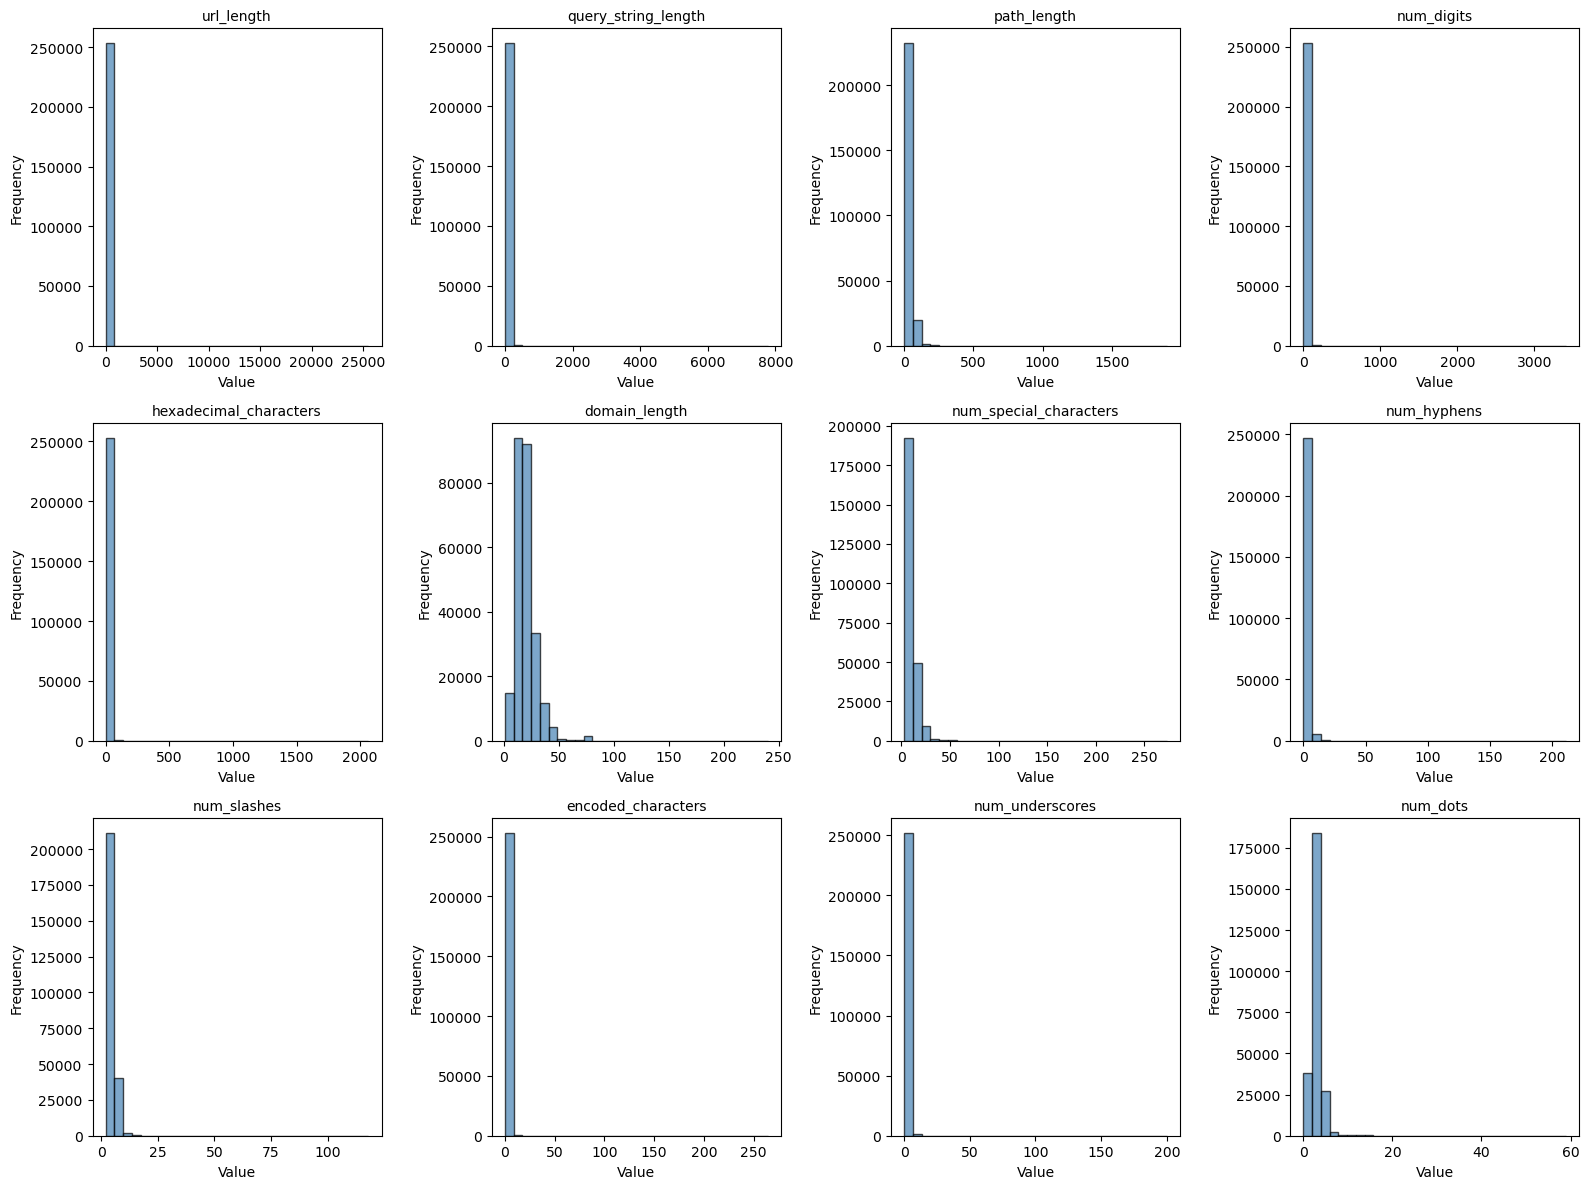

✅ Feature distributions saved!


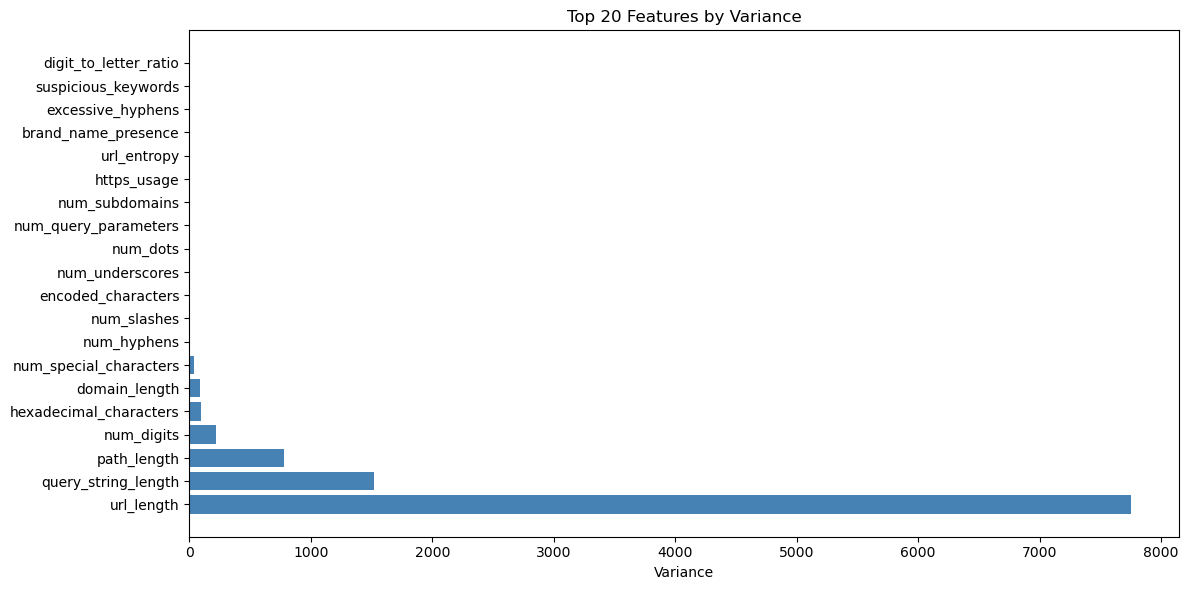

✅ Feature variance plot saved!


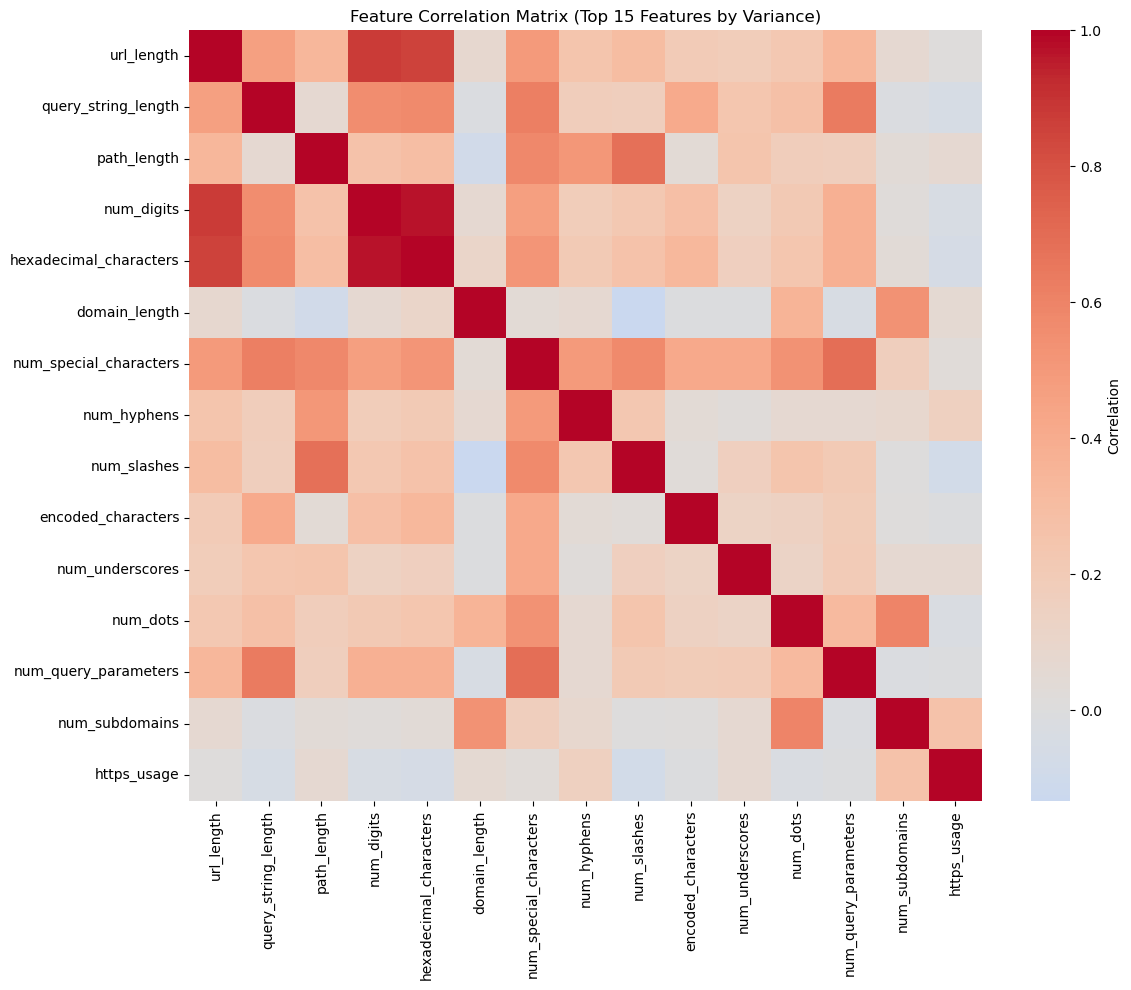

✅ Feature correlation heatmap saved!

=== FEATURE ANALYSIS COMPLETE ===


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

project_root = Path.cwd().parent

# Load extracted features
features_path = project_root / "data" / "processed" / "url_features.csv"
df_features = pd.read_csv(features_path)

print("Feature data loaded.")
print(f"Shape: {df_features.shape}")
print(f"Columns: {df_features.columns.tolist()[:5]}...")

# SELECT ONLY NUMERIC COLUMNS
df_numeric = df_features.select_dtypes(include=[np.number])

print(f"Numeric features shape: {df_numeric.shape}")

# Feature statistics
print("\n=== FEATURE STATISTICS ===")
stats = df_numeric.describe().T
print(stats)

# Save feature statistics
stats_path = project_root / "results" / "feature_importance" / "feature_statistics.csv"
stats_path.parent.mkdir(parents=True, exist_ok=True)
stats.to_csv(stats_path)
print(f"✅ Feature statistics saved!")

# Plot feature distributions (top 12 features by variance)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

top_features = df_numeric.var().nlargest(12).index

for idx, feature in enumerate(top_features):
    axes[idx].hist(df_numeric[feature].dropna(), bins=30, edgecolor='black', alpha=0.7, color='steelblue')
    axes[idx].set_title(f'{feature}', fontsize=10)
    axes[idx].set_xlabel('Value')
    axes[idx].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig(project_root / "results" / "figures" / "feature_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Feature distributions saved!")

# Feature variance (importance)
fig, ax = plt.subplots(figsize=(12, 6))

feature_variance = df_numeric.var().sort_values(ascending=False).head(20)
ax.barh(range(len(feature_variance)), feature_variance.values, color='steelblue')
ax.set_yticks(range(len(feature_variance)))
ax.set_yticklabels(feature_variance.index)
ax.set_xlabel('Variance')
ax.set_title('Top 20 Features by Variance')

plt.tight_layout()
plt.savefig(project_root / "results" / "figures" / "feature_variance.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Feature variance plot saved!")

# Feature correlation heatmap
top_15_features = df_numeric.var().nlargest(15).index
df_subset = df_numeric[top_15_features].dropna()
correlation_matrix = df_subset.corr()

correlation_matrix = correlation_matrix.fillna(0)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0, ax=ax, cbar_kws={'label': 'Correlation'})
ax.set_title('Feature Correlation Matrix (Top 15 Features by Variance)')

plt.tight_layout()
plt.savefig(project_root / "results" / "figures" / "feature_correlation_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Feature correlation heatmap saved!")

print("\n=== FEATURE ANALYSIS COMPLETE ===")